In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu130
GPU available: True


In [2]:
#Load the breast cancer dataset
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("breast-cancer.csv")

print(df.head())
print("Dataset shape:", df.shape)
print(df["diagnosis"].value_counts())

Saving breast-cancer.csv to breast-cancer.csv
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_w

In [3]:
#Prepare the data
# Remove ID because it is not a useful predictive feature
df = df.drop(columns=["id"])

# Convert labels: B = 0, M = 1
df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

# Separate features (X) and target (y)
X = df.drop(columns=["diagnosis"]).values
y = df["diagnosis"].values

# Split into training and temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split temporary data into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Fit scaling only on training data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (398, 30)
Validation: (85, 30)
Testing: (86, 30)


In [4]:
#Convert data into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(
    y_train, dtype=torch.float32
).reshape(-1, 1)

y_val = torch.tensor(
    y_val, dtype=torch.float32
).reshape(-1, 1)

y_test = torch.tensor(
    y_test, dtype=torch.float32
).reshape(-1, 1)

print("Feature tensor shape:", X_train.shape)
print("Target tensor shape:", y_train.shape)

Feature tensor shape: torch.Size([398, 30])
Target tensor shape: torch.Size([398, 1])


In [5]:
#Design the deep learning model
class BreastCancerModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(30, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


model = BreastCancerModel()

print(model)

BreastCancerModel(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [6]:
#Define the loss function and optimizer
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [7]:
#Train the model with Early Stopping
epochs = 50
patience = 10

best_val_loss = float("inf")
best_weights = None
wait = 0

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training phase
    model.train()
    optimizer.zero_grad()

    train_logits = model(X_train)
    train_loss = criterion(train_logits, y_train)

    train_loss.backward()
    optimizer.step()

    # Validation phase
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val)
        val_loss = criterion(val_logits, y_val)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    # Save the best model
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_weights = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }
        wait = 0
    else:
        wait += 1

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Train Loss = {train_loss.item():.4f}, "
            f"Val Loss = {val_loss.item():.4f}"
        )

    if wait >= patience:
        print("Early stopping triggered.")
        break

# Restore best validation weights
model.load_state_dict(best_weights)

print("Training completed.")

Epoch 10: Train Loss = 0.5869, Val Loss = 0.5709
Epoch 20: Train Loss = 0.4695, Val Loss = 0.4543
Epoch 30: Train Loss = 0.3425, Val Loss = 0.3300
Epoch 40: Train Loss = 0.2288, Val Loss = 0.2230
Epoch 50: Train Loss = 0.1529, Val Loss = 0.1550
Training completed.


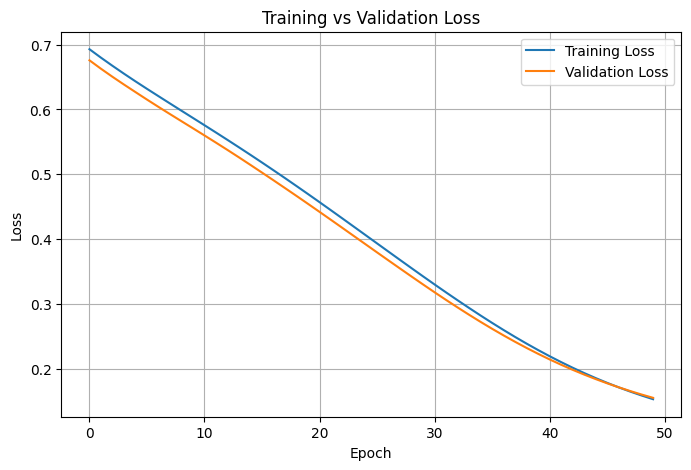

In [8]:
#Plot the training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
#Evaluate the model
model.eval()

with torch.no_grad():
    logits = model(X_test)

    probabilities = torch.sigmoid(logits)

    predictions = (
        probabilities >= 0.5
    ).int().cpu().numpy().ravel()

    actual = y_test.cpu().numpy().ravel().astype(int)

print("Test Accuracy:",
      accuracy_score(actual, predictions))

print("\nClassification Report:")
print(classification_report(
    actual,
    predictions,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(actual, predictions))

Test Accuracy: 0.9767441860465116

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        54
   Malignant       1.00      0.94      0.97        32

    accuracy                           0.98        86
   macro avg       0.98      0.97      0.97        86
weighted avg       0.98      0.98      0.98        86

Confusion Matrix:
[[54  0]
 [ 2 30]]
